<a href="https://colab.research.google.com/github/nastyaatt/IAD_tykhonova/blob/main/tykhonova_lab2_iad.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Лабораторна робота №2**
**ФБ-62мп Тихонова Анастасія**

***Завдання 1. PCA і t-SNE***




In [1]:
import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, silhouette_score

In [3]:
df = pd.read_csv("cybersecurity_network_logs.csv")
df = pd.get_dummies(df, columns=["Protocol"], dtype=int) # текст переводжу у числа

X = df.drop("Is_Malicious", axis=1) # ознаки
y = df["Is_Malicious"] # відповідь

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train) #
X_test = scaler.transform(X_test)

PCA створює нові ознаки з початкових і дозволяє залишити менше ознак, зберігши більшість інформації. Залтшаємо стільки компонент, щоб зберегти 90% інформації

In [4]:
pca = PCA(n_components=0.90) # залишаю 90% інформації
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

print("Ознак було:", X_train.shape[1])
print("Ознак стало:", X_train_pca.shape[1])
print("Збережено інформації:", round(pca.explained_variance_ratio_.sum() * 100, 1), "%")

Ознак було: 7
Ознак стало: 5
Збережено інформації: 92.0 %


**Результат**

---

Було 7 ознак, стало 5, і збережено 92% інформації



---
Навчаю Random Forest (найкращу модель з першої лаби) на даних без PCA і з PCA та порівнюємо якість і час навчання


In [5]:
start = time.time()
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)
print("Без PCA. Час навчання:", round(time.time() - start, 2), "c")
print(classification_report(y_test, model.predict(X_test)))

start = time.time()
model_pca = RandomForestClassifier(random_state=42)
model_pca.fit(X_train_pca, y_train)
print("З PCA Час навчання:", round(time.time() - start, 2), "c")
print(classification_report(y_test, model_pca.predict(X_test_pca)))

Без PCA. Час навчання: 2.44 c
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      4751
           1       0.98      0.91      0.94       249

    accuracy                           0.99      5000
   macro avg       0.99      0.95      0.97      5000
weighted avg       0.99      0.99      0.99      5000

З PCA Час навчання: 9.26 c
              precision    recall  f1-score   support

           0       0.99      1.00      1.00      4751
           1       0.97      0.90      0.94       249

    accuracy                           0.99      5000
   macro avg       0.98      0.95      0.97      5000
weighted avg       0.99      0.99      0.99      5000



**Висновки:**


---




*   Ознаки зменшились з 7 до 5
*   Якість майже не змінилась. Для шкідливого класу (1) F1 = 0,94 в обох випадках, recall 0,91 без PCA і 0,90 з PCA


*   Час навчання не зменшився, а збільшився. Дерева добре працюють із початковими ознаками, а PCA перетворює їх на складніші неперервні числа

Отже для 7 ознак PCA не потрібна. Вона буде кориснішою, коли ознак буде багато








t-SNE малює дані на 2D-карті так, щоб схожі об'єкти опинялись поруч. Оскільки він повільний, то беру випадкові 4000 об'єктів

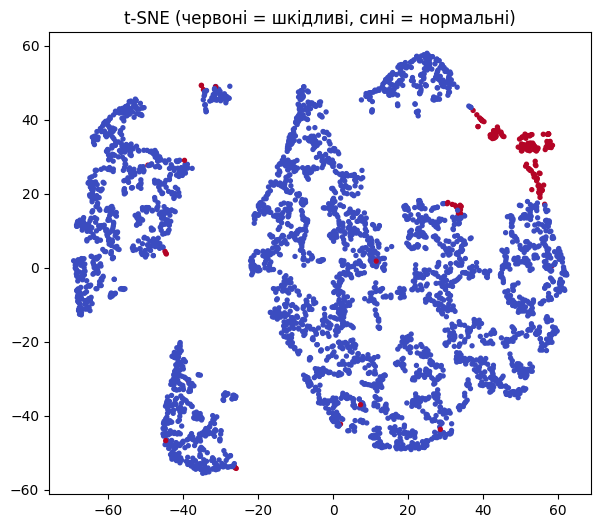

In [6]:
X_all = StandardScaler().fit_transform(X)
idx = np.random.RandomState(42).choice(len(X_all), 4000, replace=False)

X_tsne = TSNE(n_components=2, random_state=42).fit_transform(X_all[idx])

plt.figure(figsize=(7, 6))
plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=y.values[idx], cmap="coolwarm", s=8)
plt.title("t-SNE (червоні = шкідливі, сині = нормальні)")
plt.show()

Сині точку тут це нормальні з'єднання, і вони утворюють кілька великих островків. Червоні точки це шкідливі з'єднання, і як можна помітити, здебільшого вони зібрані в окрему компактну групу. Тобто шкідливий трафік добре відрізняється від нормального.

---

Але можна помітити кілька червоних точок, які потрапили до синіх. Це атаки, які схожі на нормальний трафік

***Завдання 2. K-Means***

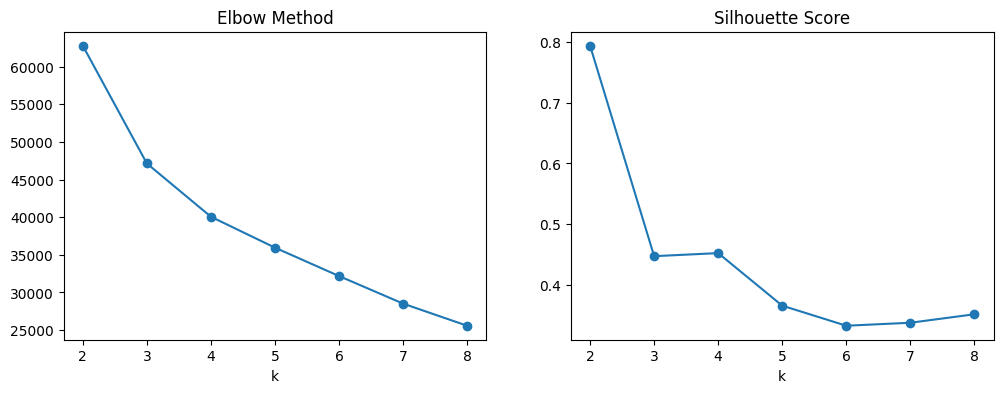

Silhouette: [np.float64(0.79), np.float64(0.45), np.float64(0.45), np.float64(0.37), np.float64(0.33), np.float64(0.34), np.float64(0.35)]


In [7]:
cols = ["Packet_Size_Bytes", "Connection_Duration_ms", "Failed_Logins", "Geo_Distance_km"]
X_num = StandardScaler().fit_transform(df[cols])

inertia = []
silh = []
for k in range(2, 9):
  km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_num)
  inertia.append(km.inertia_)
  silh.append(silhouette_score(X_num, km.labels_, sample_size=3000, random_state=42))

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(range(2, 9), inertia, "o-")
plt.title("Elbow Method")
plt.xlabel("k")
plt.subplot(1, 2, 2)
plt.plot(range(2, 9), silh, "o-")
plt.title("Silhouette Score")
plt.xlabel("k")
plt.show()
print("Silhouette:", [round(s, 2) for s in silh])

На графіку Elbow чіткого "ліктя" немає (тут значення спадають плавно). Silhouette для k = 2 дорівнює 0.79, а для інших k лише 0.45 і менше. Тому обираємо k = 2

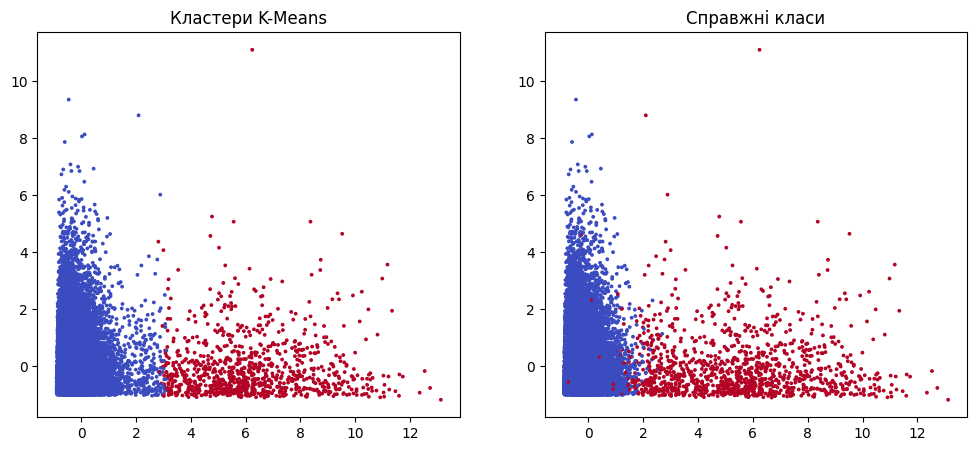

Справжній клас      0    1
Кластер                   
0               23753  325
1                   0  922


In [8]:
km = KMeans(n_clusters=2, n_init=10, random_state=42).fit(X_num)
clusters = km.labels_

X_2d = PCA(n_components=2).fit_transform(X_num)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=clusters, cmap="coolwarm", s=3)
plt.title("Кластери K-Means")
plt.subplot(1, 2, 2)
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=y, cmap="coolwarm", s=3)
plt.title("Справжні класи")
plt.show()

print(pd.crosstab(clusters, y, rownames=["Кластер"], colnames=["Справжній клас"]))

**Висновок:**


---


*   Кластер 1 (922 об'єкти) складається лише зі шкідливих з'єднань
*   Кластер 0 містить усі 23753 нормальні та 325 шкідливих


*   Тобто K-Means без жодних міток знайшов приблизно 74% атак (922 з 1247). Решта 325 атак схожі на нормальний трафік і потрапили в кластер 0
*   Структура кластерів значною мірою відповідає реальним класам, бо атаки сильно відрізняються за розіром пакета, невдалими входами та відстанню






***Завдання 3. Тексти***

Тут вже використано інший датасет, а саме SMS Spam Collection
Колонка **sms** (текст), **label** (0 - звичайне повідомлення, 1 - спам)

In [10]:
from wordcloud import WordCloud, STOPWORDS
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

sms = pd.read_csv("train.csv")
sms["sms"] = sms["sms"].str.strip() # прибираю зайві пробіли та переноси
sms = sms.drop_duplicates() # видаляю однаокві повідомлення
print(sms.shape)
print(sms["label"].value_counts())

(5160, 2)
label
0    4518
1     642
Name: count, dtype: int64


Після видалення дублікатів лишилось 5160 повідомлень: 4518 звичайних і 642 спамових. Спаму значно менше, тому далі дивитимемось на precision, recall та F1 саме для спаму


---

Передобробка: переводжу текст у нижній регістр, прибираю пунктуацію та цифри, а стоп-слова (службові слова на кшталт *the, is, and*) прибирає WordCloud

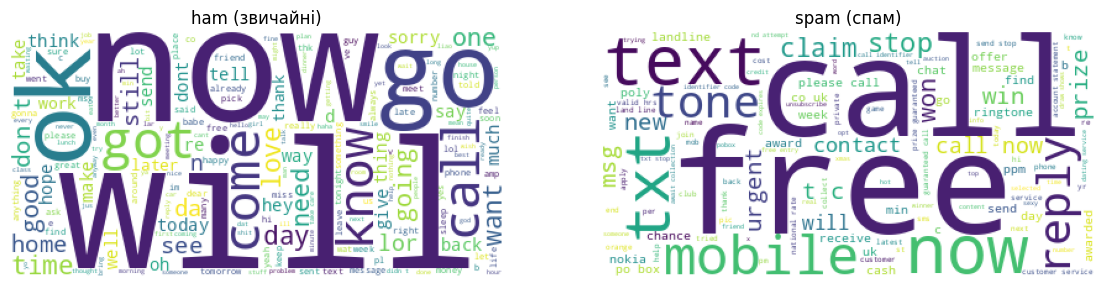

In [11]:
# нижній регістр і прибираю усі, окрім літер
sms["clean"] = sms["sms"].str.lower().str.replace("[^a-z ]", " ", regex=True)

# стоп-слова і кілька смс скорочень
stopwords = STOPWORDS | {"u", "ur", "ll", "lt", "gt", "s", "m", "p"}

plt.figure(figsize=(14, 5))
for i, label in enumerate([0, 1]):
  text = " ".join(sms[sms["label"] == label]["clean"])
  cloud = WordCloud(stopwords=stopwords, background_color="white", random_state=42).generate(text)
  plt.subplot(1, 2, i + 1)
  plt.imshow(cloud)
  plt.axis("off")
  plt.title("ham (звичайні)" if label == 0 else "spam (спам)")
plt.show()



* У спамі найбільші слова: free, call, text, txt, mobile, reply, stop, claim, prize, won, win, urgent. Це пропозиції призів і заклики до дії

* У звичайних повідомленнях: ok, got, come, know, time, day, love, want, need, home. Це повсякденна розмовна лексика


*   Проте деякі слова (call, now) є в обох класах, тому надалі буду використовувати TF-IDF


TF-IDF перетворює текст на числа, тобто слово має більшу вагу, якщо воно часто трапляється в повідомленні, але рідко в інших. Для класифікації беру логістичну регресію з class_weight="balanced", щоб модель не ігнорувала рідкісний клас (спам)



In [12]:
X_tr, X_te, y_tr, y_te = train_test_split(sms["clean"], sms["label"], test_size=0.2, random_state=42, stratify=sms["label"])

tfidf = TfidfVectorizer(stop_words="english")
A = tfidf.fit_transform(X_tr)
B = tfidf.transform(X_te)

clf = LogisticRegression(max_iter=1000, class_weight="balanced")
clf.fit(A, y_tr)
print(classification_report(y_te, clf.predict(B), target_names=["ham", "spam"]))

              precision    recall  f1-score   support

         ham       0.99      0.98      0.99       904
        spam       0.89      0.94      0.91       128

    accuracy                           0.98      1032
   macro avg       0.94      0.96      0.95      1032
weighted avg       0.98      0.98      0.98      1032



**Висновок:**


---


Для спаму precision = 0,89, recall = 0,94, F1 = 0,91. Тобто з 128 спамових повідомлень у тесті знайдено 120. Загальна accuracy = 0,98, але через дисбаланс (88 % звичайних) головне дивитись саме на показники для спаму

**Загальні висновки по роботі**


---



*   PCA зменшила ознаки з 7 до 5 (92 % інформації), якість майже не змінилась, але навчання стало довшим
*   t-SNE і K-Means показали, що шкідливий трафік утворює окрему групу: найкраща кількість кластерів k = 2, один кластер складається лише зі шкідливих з'єднань. Але кластер і клас не одне й те саме (частина атак схожа на нормальний трафік)


*   У класифікації текстів TF-IDF і логістична регресія дали F1 = 0,91 для спаму



